# Refresh policy: maximum mask age and residual signals

Until now the client sent every 5th frame. Here the client decides itself when to ask for a new mask. The first run uses only the simplest rule, a maximum mask age of 30 frames, and logs the residual signals on every frame, so I can see whether they say anything about how good the propagated mask still is before I use them as a trigger. Then I use them as a trigger and compare that with fixed intervals at the same number of requests.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

import client
import pipeline as p

RESULTS_PATH = "results/policy_frames_dev.csv"
DELAY_RESULTS_PATH = "results/delay_frames.csv"
RUN_POLICY = False  # replays the 12 development sequences in real time and takes about 9 minutes

## How it works

The client (`policy_client.py`) replays the frames at 10 fps as before and moves the mask with optical flow. On every frame a policy decides whether to send the current frame to the segmenter.

The policy here is `max_interval` with K = 30: send when there is no mask yet, or when the shown mask was segmented from a frame at least 30 frames ago. Two rules hold for all adaptive policies: at least 3 frames between two requests, and at most 2 requests waiting for an answer. Also nothing is sent while a request newer than the shown mask is already on its way.

The segmenter ran on the cluster (a V100 GPU) and the client on my laptop, connected through an SSH tunnel. No extra delay is added, so the latency is the real time for the network and the segmentation.

On every frame the client also computes two residual signals. It warps the previous grayscale frame onto the current one with the flow it already has, removes the mean brightness of each frame and takes the absolute difference. Where the flow explains the image well the residual is small.

- **Boundary residual:** the mean residual in a 7 px band around the boundary of the propagated mask, summed over the frames since the mask's source frame.
- **Tile fraction:** the image is split into 32×32 tiles. The share of tiles without mask pixels whose mean residual is above 12 gray levels. This should react to new objects.

The policy does not use these signals in this run, they are only logged.

In [2]:
if RUN_POLICY:
    subprocess.run([sys.executable, "policy_client.py", "--policies", "max_interval", "--k", "30", "--delays", "0"], check=True)

results = pd.read_csv(RESULTS_PATH, dtype={"seq": str})
delay_results = pd.read_csv(DELAY_RESULTS_PATH, dtype={"seq": str})

## Results

For comparison I take the flow run without added delay from `delay.ipynb`, which sent every 5th frame.

In [3]:
fixed = delay_results[(delay_results["method"] == "flow") & (delay_results["delay_ms"] == 0)]
summary = pd.DataFrame({
    "every 5th frame": client.summarize(fixed),
    "maximum age 30": client.summarize(results),
}).T
summary["requests_s"] = summary["requests"] / (len(results) / p.FPS)
summary[["iou", "mask_age", "requests", "requests_s", "up_kbit_s", "latency_ms"]].round(3)

,iou,mask_age,requests,requests_s,up_kbit_s,latency_ms
every 5th frame,0.809,3.001,1010.0,2.009,2090.514,113.160
maximum age 30,0.550,15.487,172.0,0.342,355.423,113.407


With a maximum age of 30 frames the client sends 172 requests instead of 1,010, about one every 3 seconds, and the upload falls from 2.1 Mbit/s to 355 kbit/s. The IoU falls from 0.81 to 0.55, because the masks are on average 15.5 frames old instead of 3.

The latency is counted until the mask is used, and the client looks for answers once per frame, so it comes in steps of one frame period. About 9 in 10 masks were used on the next frame (about 95 ms) and the rest one frame later (about 195 ms). The local run in `delay.ipynb` had the same mean latency, 113 ms, so the tunnel and the cluster add no delay that matters at 10 fps.

In [4]:
latency_ms = results["latency"].dropna() * 1e3
latency_ms.describe(percentiles=[0.5, 0.9]).round(1)

count    172.0
mean     113.4
std       37.6
min       87.5
50%       95.3
90%      193.5
max      197.1
Name: latency, dtype: float64

## Accuracy against mask age

Here the mask gets up to 30 frames old, much older than in the earlier runs, so I can see how far flow propagation carries a mask.

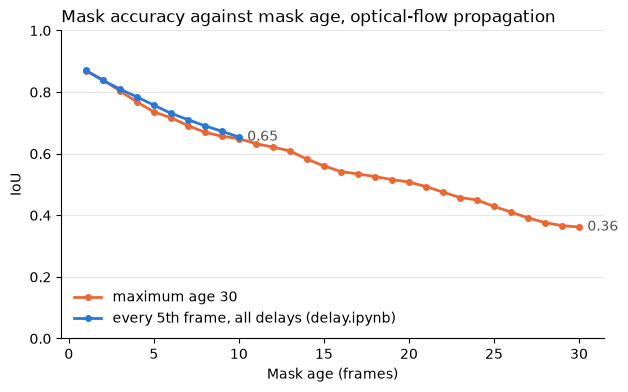

In [5]:
LABELS = {"policy": "maximum age 30", "delay": "every 5th frame, all delays (delay.ipynb)"}
COLOURS = {"policy": "#eb6834", "delay": "#2a78d6"}

def iou_by_age(frames):
    g = frames.groupby("mask_age")[["intersection", "union"]].sum()
    return g["intersection"] / g["union"]

by_age = {"policy": iou_by_age(results[results["mask_age"] <= 30]),
          "delay": iou_by_age(delay_results[delay_results["method"] == "flow"])}

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in by_age.items():
    ax.plot(s.index, s.values, color=COLOURS[name], linewidth=2, marker="o", markersize=4, label=LABELS[name])
    ax.annotate(f"{s.values[-1]:.2f}", (s.index[-1], s.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xticks(range(0, 31, 5))
ax.set_xlabel("Mask age (frames)")
ax.set_ylabel("IoU")
ax.set_ylim(0, 1)
ax.set_title("Mask accuracy against mask age, optical-flow propagation", loc="left")
ax.legend(frameon=False, loc="lower left");

Flow keeps the mask useful for a while, but not for 30 frames. The IoU falls from 0.87 at age 1 to 0.65 at age 10, 0.51 at age 20 and 0.36 at age 30. It falls fastest in the first 5 frames and then about one point of IoU per frame.

For the ages both runs have, 1 to 10, the curves are close: equal for ages 1 and 2 and up to about 0.02 lower here after that. The frames with a given age are not the same in the two runs, so I do not read more into the small difference.

## The residual signals

A useful trigger should rise when the propagated mask gets worse. The age already tells a lot about that, so the question is whether a signal tells more than the age.

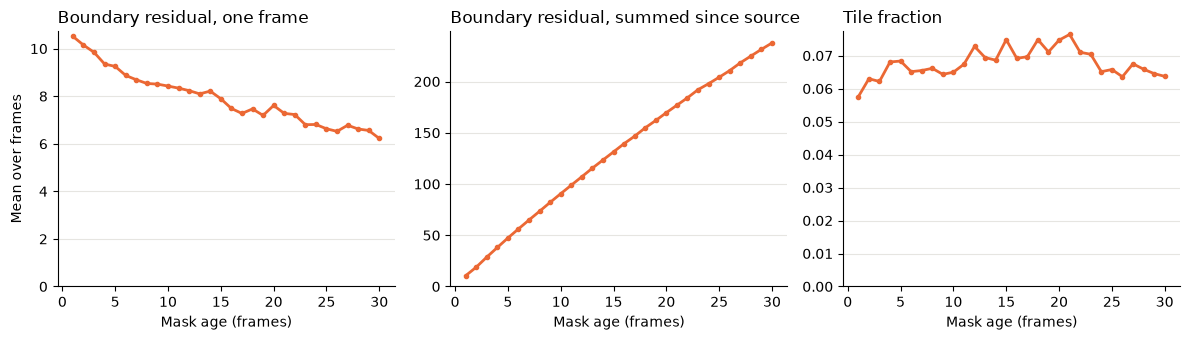

In [6]:
signals = results[results["mask_age"] <= 30].groupby("mask_age")[["residual_boundary", "residual_boundary_acc", "residual_tiles"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column, title in zip(axes, signals.columns,
                             ["Boundary residual, one frame", "Boundary residual, summed since source", "Tile fraction"]):
    ax.plot(signals.index, signals[column], color="#eb6834", linewidth=2, marker="o", markersize=3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Mask age (frames)")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("Mean over frames")
fig.tight_layout();

The boundary residual of a single frame is about 10 gray levels at age 1 and decreases slowly to about 6 at age 30. So even a fresh mask has a clear residual around its boundary: the flow never explains the image perfectly, and object edges are where it is worst. Summed since the source frame, the signal grows almost linearly with the age, to about 90 at age 10 and 240 at age 30.

The tile fraction stays flat at about 0.06 to 0.075 and does not depend on the age, which is expected, since it looks at the image outside the mask.

The threshold of 30 that I had guessed for the summed boundary residual is far too low. It is reached at a median age of 4 frames, so a policy with it would send almost every 3 frames, the minimum interval allowed.

### Do the signals say more than the age?

For every mask I take the IoU on the frame where it was first used (age 1), and for every later frame how much the IoU has dropped since. Then for each age separately I compute the rank correlation between a signal and this drop. A positive value means that among masks of the same age, those with a higher signal have lost more accuracy. I leave out frames with very small objects (union below 2,000 pixels), where the IoU of a single frame jumps around.

boundary    0.329
tiles       0.252
dtype: float64

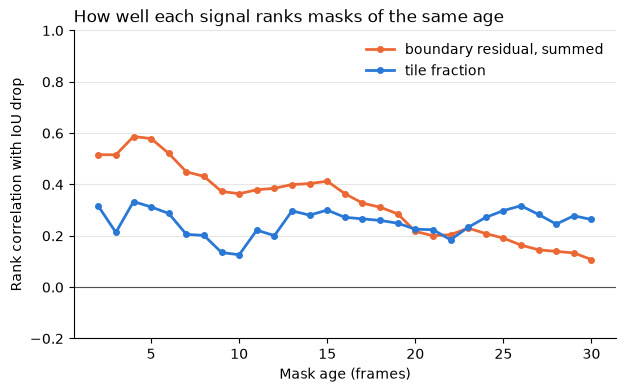

In [7]:
frames = results.copy()
frames["source"] = frames["time_frame"] - frames["mask_age"]
frames["frame_iou"] = frames["intersection"] / frames["union"].where(frames["union"] > 0)
first = frames[frames["mask_age"] == 1].set_index(["seq", "source"])["frame_iou"].rename("first_iou")
frames = frames.join(first, on=["seq", "source"])
frames["iou_drop"] = frames["first_iou"] - frames["frame_iou"]

usable = frames.dropna(subset=["iou_drop", "residual_boundary_acc"])
usable = usable[(usable["union"] > 2000) & usable["mask_age"].between(2, 30)]

def rank_corr(a, b):
    return a.rank().corr(b.rank())

corr = usable.groupby("mask_age").apply(lambda g: pd.Series({
    "boundary": rank_corr(g["residual_boundary_acc"], g["iou_drop"]),
    "tiles": rank_corr(g["residual_tiles"], g["iou_drop"]),
}), include_groups=False)

fig, ax = plt.subplots(figsize=(7, 4))
for column, colour, label in [("boundary", "#eb6834", "boundary residual, summed"), ("tiles", "#2a78d6", "tile fraction")]:
    ax.plot(corr.index, corr[column], color=colour, linewidth=2, marker="o", markersize=4, label=label)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Mask age (frames)")
ax.set_ylabel("Rank correlation with IoU drop")
ax.set_ylim(-0.2, 1)
ax.set_title("How well each signal ranks masks of the same age", loc="left")
ax.legend(frameon=False, loc="upper right")
corr.mean().round(3)

Both signals carry information that the age does not have. For young masks the summed boundary residual is the better one: at ages 2 to 5 its rank correlation with the IoU drop is about 0.5 to 0.6. It gets weaker with age, down to about 0.1 at age 30. The tile fraction is weaker but steady, mostly between 0.2 and 0.3 at all ages.

This is the useful case for a trigger. The policy has to decide early, while the mask is still young, whether it has gone bad faster than usual, and that is where the boundary signal is strongest. Each age has only about 125 masks, so the single points are noisy, but the trend is clear.

The signals also differ between sequences. Sequences with a high boundary residual tend to have a low IoU, for example 0003 (residual 12.0, IoU 0.24) against 0009 (residual 4.5, IoU 0.69). A fixed threshold would then send more often in the hard sequences, which is what we want.

In [8]:
per_seq = results.groupby("seq").agg(frames=("time_frame", "size"), intersection=("intersection", "sum"), union=("union", "sum"),
                                     boundary=("residual_boundary", "mean"), tiles=("residual_tiles", "mean"))
per_seq["iou"] = per_seq["intersection"] / per_seq["union"]
per_seq[["frames", "iou", "boundary", "tiles"]].round(3)

,frames,iou,boundary,tiles
seq,,,,
0000,154,0.425,8.345,0.081
0001,447,0.565,8.013,0.088
0003,144,0.238,11.978,0.347
0004,314,0.303,13.193,0.103
0005,297,0.301,9.711,0.075
0009,803,0.686,4.464,0.097
0011,373,0.623,7.930,0.058
0012,78,0.315,3.760,0.000
0015,376,0.713,5.204,0.030


## Choosing thresholds

For the next run I take thresholds from the distribution of the signals instead of guessing. For the summed boundary residual, values that are reached around ages 8 to 15 on average. For the tile fraction, the 90th, 95th and 99th percentiles, so that it fires on a small share of frames.

In [9]:
pd.DataFrame({
    "boundary residual, summed": results["residual_boundary_acc"].quantile([0.5, 0.8, 0.9, 0.95, 0.99]),
    "tile fraction": results["residual_tiles"].quantile([0.5, 0.8, 0.9, 0.95, 0.99]),
}).round(3)

,"boundary residual, summed",tile fraction
0.50,114.439,0.034
0.80,212.954,0.112
0.90,267.569,0.172
0.95,312.144,0.230
0.99,424.528,0.454


Candidates for the tuning run:

- summed boundary residual: 60, 100 and 150, which the mean mask reaches at about ages 6, 11 and 17
- tile fraction: 0.17, 0.23 and 0.45, the 90th, 95th and 99th percentiles

## Traffic and client time

In [10]:
client_time = pd.Series({
    "client_ms": results["step_time"].mean() * 1e3,
    "trigger_ms": results["trigger_time"].mean() * 1e3,
    "late": (results["step_time"] > 1 / p.FPS).mean(),
})
client_time.round(3)

client_ms     17.562
trigger_ms     3.947
late           0.000
dtype: float64

The client needs about 18 ms per frame, of which about 4 ms are the two residual signals. No frame took longer than the 100 ms frame period. The signals were computed here although the policy did not use them, so for the comparison of costs the 4 ms count only for the residual policy.

## Comparing the policies

With the thresholds from above I ran the residual policy and fixed intervals on the development sequences. All runs use the segmenter on the cluster without added delay. I ran three at a time, each with its own segmenter process on the same GPU.

- **fixed:** every 5th, 10th and 20th frame
- **residual, boundary only:** maximum age 30 plus the summed boundary residual with thresholds 60, 100 and 150
- **residual, tiles only:** maximum age 30 plus the tile fraction with thresholds 0.23 and 0.45
- **residual, both:** maximum age 30, boundary 100 and tiles 0.45

I left out the maximum-interval rule as its own policy. With answers that arrive after one frame it sends on the same frames as a fixed interval: the run with maximum age 30 above sent 172 requests, and every 30th frame gives exactly 172 too. So I count that run as fixed with N = 30.

In [11]:
RUN_COMPARISON = False
RUNS = {
    "results/policy_fixed.csv": ["--policies", "fixed", "--n", "5", "10", "20"],
    "results/policy_boundary.csv": ["--policies", "residual", "--k", "30", "--t-boundary", "60", "100", "150", "--t-tiles", "none"],
    "results/policy_tiles.csv": ["--policies", "residual", "--k", "30", "--t-boundary", "none", "--t-tiles", "0.23", "0.45"],
    "results/policy_both.csv": ["--policies", "residual", "--k", "30", "--t-boundary", "100", "--t-tiles", "0.45"],
}
if RUN_COMPARISON:
    for out, args in RUNS.items():
        subprocess.run([sys.executable, "policy_client.py", "--delays", "0", "--out", out, *args], check=True)

runs = pd.concat([pd.read_csv(path, dtype={"seq": str}) for path in [RESULTS_PATH, *RUNS]], ignore_index=True)
is_k30 = runs["policy"] == "max_interval"
runs.loc[is_k30, "policy"] = "fixed"
runs.loc[is_k30, "params"] = "N=30"

def group(policy, params):
    if policy == "fixed":
        return "fixed"
    if "tb" in params and "tt" in params:
        return "both"
    return "boundary" if "tb" in params else "tiles"

runs["group"] = [group(a, b) for a, b in zip(runs["policy"], runs["params"])]
runs["setting"] = runs["params"].str.replace("K=30,", "").str.replace("tb=", "boundary ").str.replace("tt=", "tiles ").str.replace(".0", "", regex=False)

def rate_and_iou(frames):
    return pd.Series({
        "iou": frames["intersection"].sum() / frames["union"].sum(),
        "requests_s": frames["sent"].sum() / (len(frames) / p.FPS),
        "mask_age": frames["mask_age"].mean(),
    })

comparison = runs.groupby(["group", "setting"]).apply(rate_and_iou, include_groups=False)
comparison.round(3)

iou  requests_s  mask_age
group    setting                                             
both     boundary 100,tiles 0.45  0.723       0.885     8.036
boundary boundary 100             0.721       0.843     8.357
         boundary 150             0.646       0.585    11.251
         boundary 60              0.785       1.390     5.708
fixed    N=10                     0.739       1.011     5.812
         N=20                     0.597       0.509    12.789
         N=30                     0.550       0.342    15.487
         N=5                      0.808       2.009     3.172
tiles    tiles 0.23               0.584       0.493    14.437
         tiles 0.45               0.552       0.380    15.386

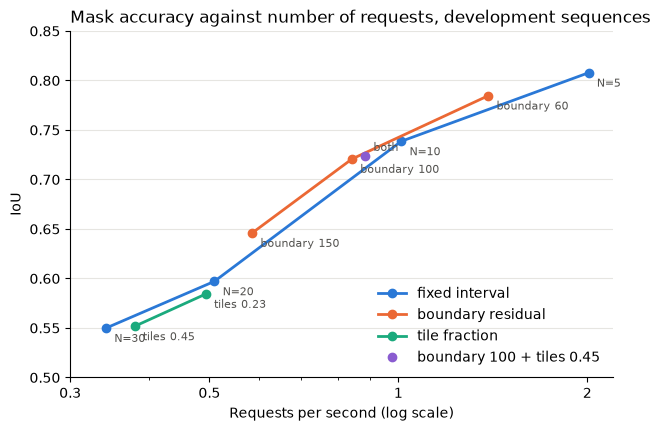

In [12]:
GROUP_LABELS = {"fixed": "fixed interval", "boundary": "boundary residual", "tiles": "tile fraction", "both": "boundary 100 + tiles 0.45"}
GROUP_COLOURS = {"fixed": "#2a78d6", "boundary": "#eb6834", "tiles": "#1baa7d", "both": "#8a5cd0"}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in ["fixed", "boundary", "tiles", "both"]:
    s = comparison.loc[name].sort_values("requests_s")
    ax.plot(s["requests_s"], s["iou"], color=GROUP_COLOURS[name], linewidth=2 if len(s) > 1 else 0,
            marker="o", markersize=6, label=GROUP_LABELS[name])
    for setting, row in s.iterrows():
        ax.annotate("both" if name == "both" else setting, (row["requests_s"], row["iou"]),
                    xytext=(6, 4) if name == "both" else (6, -10), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 2])
ax.set_xticklabels(["0.3", "0.5", "1", "2"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Requests per second (log scale)")
ax.set_ylabel("IoU")
ax.set_ylim(0.5, 0.85)
ax.set_title("Mask accuracy against number of requests, development sequences", loc="left")
ax.legend(frameon=False, loc="lower right");

A policy is better when its points lie above the fixed curve: more accuracy for the same number of requests. The boundary residual lies a little above the fixed curve at all three thresholds. The tile fraction lies a little below it.

### At the same number of requests

The residual runs do not hit exactly the request rates of the fixed runs, so I interpolate the fixed curve at the rate of each residual run, linearly over the logarithm of the rate. In the other direction, I also compute how many requests fixed intervals would need for the same IoU.

The same comparison per sequence shows whether a gain is spread over the sequences or comes from a few of them. Here I compare with each sequence's own fixed curve and count only the sequences where the residual run's rate lies inside the range of the fixed runs.

In [13]:
import numpy as np

def fixed_iou_at(rate, fixed):
    fixed = fixed.sort_values("requests_s")
    return np.interp(np.log(rate), np.log(fixed["requests_s"]), fixed["iou"])

def fixed_rate_for(iou, fixed):
    fixed = fixed.sort_values("iou")
    return np.exp(np.interp(iou, fixed["iou"], np.log(fixed["requests_s"])))

per_seq = runs.groupby(["group", "setting", "seq"]).apply(rate_and_iou, include_groups=False)
fixed_all = comparison.loc["fixed"]
rows = {}
for (name, setting), row in comparison.drop("fixed").iterrows():
    better = compared = 0
    for seq in runs["seq"].unique():
        fixed_seq = per_seq.loc["fixed"].xs(seq, level="seq")
        own = per_seq.loc[(name, setting, seq)]
        if fixed_seq["requests_s"].min() < own["requests_s"] < fixed_seq["requests_s"].max():
            compared += 1
            better += own["iou"] > fixed_iou_at(own["requests_s"], fixed_seq)
    same_rate = fixed_iou_at(row["requests_s"], fixed_all)
    rows[setting] = {
        "requests_s": row["requests_s"],
        "iou": row["iou"],
        "fixed_same_rate": same_rate,
        "gain": row["iou"] - same_rate,
        "fewer_requests": 1 - row["requests_s"] / fixed_rate_for(row["iou"], fixed_all),
        "sequences_better": f"{better} of {compared}",
    }
pd.DataFrame(rows).T.astype({key: float for key in ["requests_s", "iou", "fixed_same_rate", "gain", "fewer_requests"]}).round(3)

,requests_s,iou,fixed_same_rate,gain,fewer_requests,sequences_better
"boundary 100,tiles 0.45",0.885,0.723,0.711,0.012,0.057,6 of 12
boundary 100,0.843,0.721,0.701,0.019,0.090,7 of 12
boundary 150,0.585,0.646,0.626,0.020,0.093,8 of 11
boundary 60,1.390,0.785,0.771,0.014,0.129,7 of 10
tiles 0.23,0.493,0.584,0.593,-0.009,-0.079,0 of 8
tiles 0.45,0.380,0.552,0.562,-0.011,-0.094,0 of 3


The boundary residual is better than fixed intervals at all three thresholds, by 0.014 to 0.020 IoU at the same number of requests. Put the other way, fixed intervals need about 9 to 13 % more requests for the same accuracy. The gain is not large. It holds in 7 or 8 of the compared sequences, so it is not one sequence alone, but per sequence it is often small.

The tile fraction is worse than fixed intervals, by about 0.01 IoU, and it is not better in any sequence where they can be compared. Together with the boundary residual it adds requests but hardly any accuracy, so the combination is worse than the boundary residual alone (0.012 instead of 0.019 at about the same rate). I drop the tile fraction.

### Where the tile fraction sends its requests

In [14]:
tiles_023 = per_seq.loc[("tiles", "tiles 0.23")]
tiles_023[["requests_s", "iou"]].round(2).T

seq,0000,0001,0003,0004,0005,0009,0011,0012,0015,0017,0019,0020
requests_s,0.58,0.72,2.15,0.41,0.44,0.50,0.35,0.38,0.43,0.34,0.40,0.37
iou,0.51,0.68,0.36,0.32,0.32,0.74,0.62,0.32,0.73,0.36,0.44,0.69


With threshold 0.23 the tile fraction sends 2.15 requests per second in sequence 0003 and between 0.34 and 0.72 in all the others. So it does not react to single new objects, it mostly reacts to sequence 0003, where much of the background is not explained well by the flow. That sequence has the lowest IoU, but the extra requests there do not pay off.

### The latency differs between the runs

A mask is used either one frame after its request (about 95 ms) or two frames after (about 195 ms), depending on when the answer arrives. The share of the slower case was not the same in all runs:

In [15]:
adopted = runs.dropna(subset=["latency"])
late_share = (adopted["latency"] > 0.15).groupby([adopted["group"], adopted["setting"]]).mean()
late_share.rename("used two frames later").round(2).to_frame()

used two frames later
group    setting                                       
both     boundary 100,tiles 0.45                   0.23
boundary boundary 100                              0.37
         boundary 150                              0.22
         boundary 60                               0.14
fixed    N=10                                      0.31
         N=20                                      0.22
         N=30                                      0.17
         N=5                                       0.16
tiles    tiles 0.23                                0.23
         tiles 0.45                                0.32

Between 14 and 37 % of the masks came one frame later, depending on the load of the network and the cluster during the run. One extra frame of age costs about 0.03 IoU for a young mask, so differences of 0.01 to 0.02 between runs can come from this alone.

It probably does not explain the gain of the boundary residual: the run with threshold 100, which has the largest gain at its rate, had the most late masks (37 %). But the effect is of the same size as the gain, so the result is not certain yet.

## Slower network

So far the client and the segmenter talked over a fast connection, and a mask came back after about one frame. Here I simulate a slower mobile connection on top of it, in the client (`--uplink-kbit`, `--net-delay`, `--jitter` in `policy_client.py`):

- **upload of 2 Mbit/s.** A frame is about 137 KB as JPEG, so sending it takes about 0.55 s, and a request has to wait while an earlier one is still being sent.
- **50 ms more delay** for every answer.
- **jitter:** a random extra delay, half-normal with a standard deviation of 20 ms, the same random values in every run (seed 0).

The masks coming back are small, so I do not limit the download.

On this link the maximum-interval rule is no longer the same as fixed intervals. It does not send while a newer request is on its way, so it cannot fill up the link. I run it again as its own policy, so I can tell apart what comes from the residual signal and what from this rule.

In [16]:
RUN_NETWORK = False  # 12 passes of about 9 minutes, three in parallel take about 40 minutes
LINK = ["--delays", "0", "--uplink-kbit", "2000", "--net-delay", "0.05", "--jitter", "0.02"]
NETWORK_RUNS = {
    "results/net2m_fixed.csv": ["--policies", "fixed", "--n", "5", "10", "20"],
    "results/net2m_max.csv": ["--policies", "max_interval", "--k", "5", "10", "20"],
    "results/net2m_boundary.csv": ["--policies", "residual", "--k", "30", "--t-boundary", "60", "100", "150", "--t-tiles", "none"],
}
if RUN_NETWORK:
    for out, args in NETWORK_RUNS.items():
        subprocess.run([sys.executable, "policy_client.py", *LINK, "--out", out, *args], check=True)

net = pd.concat([pd.read_csv(path, dtype={"seq": str}) for path in NETWORK_RUNS], ignore_index=True)

def network_summary(frames):
    latency = frames["latency"].dropna()
    return pd.Series({
        "iou": frames["intersection"].sum() / frames["union"].sum(),
        "requests_s": frames["sent"].sum() / (len(frames) / p.FPS),
        "mask_age": frames["mask_age"].mean(),
        "latency_median_ms": latency.median() * 1e3,
        "latency_max_ms": latency.max() * 1e3,
        "most_pending": frames["pending"].max(),
    })

net_summary = net.groupby(["policy", "params"]).apply(network_summary, include_groups=False)
net_summary.round(3)

iou  requests_s  mask_age  latency_median_ms  \
policy       params                                                          
fixed        N=10           0.607       1.011    11.932            697.662   
             N=20           0.524       0.509    16.818            698.924   
             N=5            0.447       2.009    26.945           1670.482   
max_interval K=10           0.607       1.009    11.916            696.748   
             K=20           0.521       0.509    17.048            786.468   
             K=5            0.628       1.357    10.733            689.973   
residual     K=30,tb=100.0  0.531       0.515    17.380            697.698   
             K=30,tb=150.0  0.490       0.416    19.821            711.934   
             K=30,tb=60.0   0.573       0.674    15.121            697.194   

                            latency_max_ms  most_pending  
policy       params                                       
fixed        N=10                 1178.919           2.0  
             N=20                 1093.918           1.0  
             N=5                  8287.930          17.0  
max_interval K=10                 1086.012           1.0  
             K=20                 1191.425           1.0  
             K=5                  1187.807           1.0  
residual     K=30,tb=100.0        1089.043           1.0  
             K=30,tb=150.0        1094.041           1.0  
             K=30,tb=60.0         1196.771           1.0

The answers now take about 0.7 s instead of 0.1 s, so a mask is about 7 frames old when it arrives.

**Sending every 5th frame breaks down.** It sends 2 requests per second, but the link carries only about 1.8. The requests queue up, up to 17 at once and 8 seconds of latency, and the IoU (0.45) is lower than when sending only every 20th frame (0.52). On a limited link sending more can make the masks worse.

**The maximum-interval rule with K = 5 is the best policy here (0.63).** It wants a new mask at the same age as every 5th frame, but it does not send while a request is on its way. So it sends as soon as the previous answer has come back, every 7.4 frames, and uses the link exactly as much as it can carry, without knowing its rate. With K = 10 and 20 it sends on the same frames as fixed intervals, because the link is never full.

**The residual policy sends much less than on the fast network,** threshold 100 only every 19 frames instead of every 12. The reason is a choice in how I sum the boundary residual: the sum started from zero when a new mask *arrived*. On the fast network that is one frame after its source frame. Here the mask is already 7 frames old when it arrives, and those 7 frames of drift were not counted.

### Summing from the source frame

I changed the sum: when a late mask arrives, it now starts with the boundary residuals of the frames since the mask's source frame. Those were measured around the previous mask, which was moved by the same flows, so it is an estimate. On the fast network nothing changes, because a mask arrives one frame after its source. I ran the three thresholds again with the same link.

In [17]:
FIXED_SUM_RUNS = [f"results/net2m_boundary_fix{t}.csv" for t in [60, 100, 150]]
if RUN_NETWORK:
    for out, threshold in zip(FIXED_SUM_RUNS, ["60", "100", "150"]):
        subprocess.run([sys.executable, "policy_client.py", *LINK, "--out", out, "--policies", "residual", "--k", "30",
                        "--t-boundary", threshold, "--t-tiles", "none"], check=True)

fixed_sum = pd.concat([pd.read_csv(path, dtype={"seq": str}) for path in FIXED_SUM_RUNS], ignore_index=True)
fixed_sum["policy"] = "residual, sum from source"
net.loc[net["policy"] == "residual", "policy"] = "residual, sum from arrival"
net = pd.concat([net, fixed_sum], ignore_index=True)
net_summary = net.groupby(["policy", "params"]).apply(network_summary, include_groups=False)
net_summary.loc[["residual, sum from arrival", "residual, sum from source"], ["iou", "requests_s", "mask_age"]].round(3)

iou  requests_s  mask_age
policy                     params                                    
residual, sum from arrival K=30,tb=100.0  0.531       0.515    17.380
                           K=30,tb=150.0  0.490       0.416    19.821
                           K=30,tb=60.0   0.573       0.674    15.121
residual, sum from source  K=30,tb=100.0  0.573       0.746    15.050
                           K=30,tb=150.0  0.527       0.529    17.588
                           K=30,tb=60.0   0.613       1.048    12.803

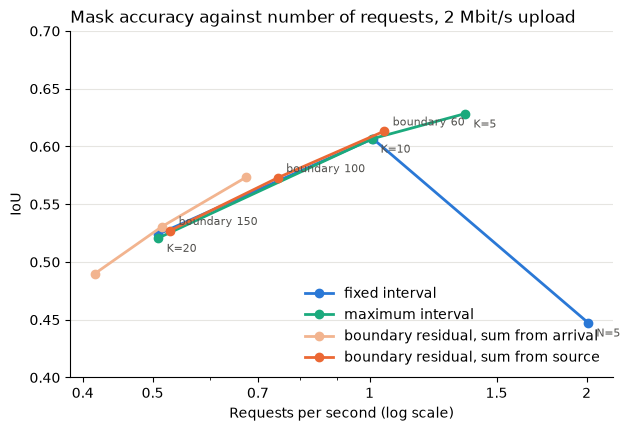

In [18]:
NET_LABELS = {"fixed": "fixed interval", "max_interval": "maximum interval",
              "residual, sum from arrival": "boundary residual, sum from arrival",
              "residual, sum from source": "boundary residual, sum from source"}
NET_COLOURS = {"fixed": "#2a78d6", "max_interval": "#1baa7d",
               "residual, sum from arrival": "#f2b48f", "residual, sum from source": "#eb6834"}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in NET_LABELS:
    s = net_summary.loc[name].sort_values("requests_s")
    ax.plot(s["requests_s"], s["iou"], color=NET_COLOURS[name], linewidth=2, marker="o", markersize=6, label=NET_LABELS[name])
    for params, row in s.iterrows():
        if name not in ["max_interval", "residual, sum from source"] and params != "N=5":
            continue  # the other points lie on top of these
        label = params.replace("K=30,", "").replace("tb=", "boundary ").replace(".0", "")
        ax.annotate(label, (row["requests_s"], row["iou"]), xytext=(6, 4) if name == "residual, sum from source" else (6, -10), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xticks([0.4, 0.5, 0.7, 1, 1.5, 2])
ax.set_xticklabels(["0.4", "0.5", "0.7", "1", "1.5", "2"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Requests per second (log scale)")
ax.set_ylabel("IoU")
ax.set_ylim(0.4, 0.7)
ax.set_title("Mask accuracy against number of requests, 2 Mbit/s upload", loc="left")
ax.legend(frameon=False, loc="lower right");

With the sum from the source frame the residual policy sends more often again, threshold 100 every 13 frames instead of 19, and reaches higher IoU. But that comes with more requests. What counts is whether it is above the maximum-interval curve at the same number of requests. I compare with the maximum-interval rule and not with fixed intervals, because it has the same rule about pending requests and is the better of the two here.

In [19]:
max_curve = net_summary.loc["max_interval"]
net_per_seq = net.groupby(["policy", "params", "seq"]).apply(network_summary, include_groups=False)
rows = {}
for name in ["residual, sum from arrival", "residual, sum from source"]:
    for params, row in net_summary.loc[name].iterrows():
        if not max_curve["requests_s"].min() <= row["requests_s"] <= max_curve["requests_s"].max():
            continue  # fewer requests than any maximum-interval run, nothing to compare with
        better = compared = 0
        for seq in net["seq"].unique():
            max_seq = net_per_seq.loc["max_interval"].xs(seq, level="seq")
            own = net_per_seq.loc[(name, params, seq)]
            if max_seq["requests_s"].min() < own["requests_s"] < max_seq["requests_s"].max():
                compared += 1
                better += own["iou"] > fixed_iou_at(own["requests_s"], max_seq)
        same_rate = fixed_iou_at(row["requests_s"], max_curve)
        rows[(name, params.replace("K=30,", ""))] = {
            "requests_s": row["requests_s"],
            "iou": row["iou"],
            "max_interval_same_rate": same_rate,
            "gain": row["iou"] - same_rate,
            "fewer_requests": 1 - row["requests_s"] / fixed_rate_for(row["iou"], max_curve),
            "sequences_better": f"{better} of {compared}",
        }
pd.DataFrame(rows).T.astype({key: float for key in ["requests_s", "iou", "max_interval_same_rate", "gain", "fewer_requests"]}).round(3)

requests_s    iou  \
residual, sum from arrival tb=100.0       0.515  0.531   
                           tb=60.0        0.674  0.573   
residual, sum from source  tb=100.0       0.746  0.573   
                           tb=150.0       0.529  0.527   
                           tb=60.0        1.048  0.613   

                                     max_interval_same_rate   gain  \
residual, sum from arrival tb=100.0                   0.522  0.008   
                           tb=60.0                    0.556  0.017   
residual, sum from source  tb=100.0                   0.569  0.004   
                           tb=150.0                   0.526  0.002   
                           tb=60.0                    0.610  0.004   

                                     fewer_requests sequences_better  
residual, sum from arrival tb=100.0           0.065           1 of 6  
                           tb=60.0            0.129           7 of 9  
residual, sum from source  tb=100.0           0.033          5 of 10  
                           tb=150.0           0.013           2 of 6  
                           tb=60.0            0.051          5 of 11

With the sum from the source frame the residual policy is only 0.002 to 0.004 IoU above the maximum-interval rule at the same number of requests, and better in only 5 of 11, 5 of 10 and 2 of 6 of the compared sequences. That is no real difference. The fix did what it should, the policy reacts earlier, but it did not make it better than a timer with the same rule about pending requests.

The old sum from arrival looked a bit better at threshold 60 (0.017, better in 7 of 9 sequences) but not at threshold 100 (0.008, better in 1 of 6). With so few sequences in the comparison and results that go both ways, I do not read a real difference between the two sums from this.

So on this link the residual signal adds almost nothing. A mask is already 7 frames old when it arrives, and the policy cannot refresh faster than one answer takes, so there is little room left for choosing a better moment. What matters is the rule that only one request is on its way at a time: it turns "every 5th frame", the worst policy here, into the best one.

## Next

- Rerun fixed intervals 5, 10, 20 and the boundary residual 60, 100, 150 on the fast network with an added delay of 150 ms. Then almost every mask is used exactly two frames after its request, and the latency is the same in all runs. This shows whether the gain of 0.02 on the fast network is real.
- Run the slow link with the maximum-interval rule at K = 3 and 7. With K = 5 it already sends as soon as the previous answer is back, so smaller K should not change anything, which would confirm that "one request on its way" is the actual policy.
- Evaluate the chosen settings on the held-out sequences.